# Maven Fuzzy Factory: E-commerce Analytics and Refund Prediction

## 1. Project Overview

**Project type:** End-to-end data analytics and exploratory machine learning  
**Domain:** E-commerce  
**Tools:** MySQL, Python, pandas, Matplotlib, scikit-learn, Jupyter Notebook

### Business problem

An e-commerce business loses money when customers return purchased items. Understanding historical refunds can help the business identify refund patterns, investigate risky products and purchasing periods, and explore whether refund risk can be predicted at the time of purchase.

This project has two connected objectives:

1. **Business analytics:** Understand sales performance, profitability, customer website activity, product performance, and refund patterns.
2. **Machine learning:** Test whether information available when an item is purchased can help predict whether that item will be refunded within 30 days.

The machine learning component is exploratory. The models developed so far are not sufficiently reliable for operational use.



In [3]:
import pandas as pd

In [4]:
df_maven= pd.read_csv('maven_fuzzy_factory_data_dictionary.csv')

In [3]:
df_order_item=pd.read_csv('order_items.csv')

In [4]:
df_order_item=pd.read_csv('order_items.csv')

In [5]:
df_item_refund=pd.read_csv('order_item_refunds.csv')

In [6]:
df_web_session=pd.read_csv('website_sessions.csv')

In [7]:
df_web_pageviews=pd.read_csv('website_pageviews.csv')

In [8]:
df_product=pd.read_csv('products.csv')

In [9]:
df_order=pd.read_csv('orders.csv')

# **2. Data Preparation and Analysis

The project used multiple related datasets covering website sessions, pageviews, orders, order items, refunds, products, and a data dictionary.

The analysis involved:

Inspecting tables and understanding their relationships.

Checking dataset sizes, missing values, duplicate records, and identifiers.

Investigating order-level and item-level information.

Connecting refund records to purchased items.

Analyzing sales, costs, gross profit, product performance, website traffic, and refund patterns.

Preparing an item-level dataset for the predictive experiment.

A key data-quality lesson was that orders and order items are not interchangeable. An order can contain multiple items, and refund prediction must use the appropriate unit of analysis.

In [10]:
df_maven.head()

,Table,Field,Description
0,orders,order_id,Unique identifier for each order (PK)
1,orders,created_at,Timestamp when the order was placed
2,orders,website_session_id,Unique identifier for the website session (FK)
3,orders,user_id,Unique identifier for the user (FK)
4,orders,primary_product_id,Unique identifier for the primary product in t...


In [11]:
df_item_refund.head()

,order_item_refund_id,created_at,order_item_id,order_id,refund_amount_usd
0,1,2012-04-06 11:32:43,57,57,49.99
1,2,2012-04-13 01:09:43,74,74,49.99
2,3,2012-04-15 07:03:48,71,71,49.99
3,4,2012-04-17 20:00:37,118,118,49.99
4,5,2012-04-22 20:53:49,116,116,49.99


In [12]:
df_order_item.head()

,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,4,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,5,1,1,49.99,19.49


In [13]:
df_maven.shape

(36, 3)

In [14]:
df_maven.isnull().sum()

Table          0
Field          0
Description    0
dtype: int64

2nd csv

In [15]:
df_order.head()

,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49


In [16]:
df_order.shape

(32313, 8)

In [17]:
df_order.isnull().sum()

order_id              0
created_at            0
website_session_id    0
user_id               0
primary_product_id    0
items_purchased       0
price_usd             0
cogs_usd              0
dtype: int64

In [18]:
df_item_refund.shape

(1731, 5)

In [19]:
df_web_session.head()

,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com


In [20]:
df_web_session.shape

(472871, 9)

In [21]:
df_web_session.isnull().sum()

website_session_id        0
created_at                0
user_id                   0
is_repeat_session         0
utm_source            83328
utm_campaign          83328
utm_content           83328
device_type               0
http_referer          39917
dtype: int64

In [22]:
df_web_pageviews.head()

,website_pageview_id,created_at,website_session_id,pageview_url
0,1,2012-03-19 08:04:16,1,/home
1,2,2012-03-19 08:16:49,2,/home
2,3,2012-03-19 08:26:55,3,/home
3,4,2012-03-19 08:37:33,4,/home
4,5,2012-03-19 09:00:55,5,/home


In [23]:
df_web_pageviews.shape

(1188124, 4)

In [24]:
df_web_pageviews.isnull().sum()

website_pageview_id    0
created_at             0
website_session_id     0
pageview_url           0
dtype: int64

In [25]:
df_product

,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda
3,4,2014-02-05 10:00:00,The Hudson River Mini bear


In [26]:
df_product.shape

(4, 3)

In [27]:
df_order.shape

(32313, 8)

In [28]:
df_order.head()

,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49


we have 7 csvs  
maven
table, fileld , discription (36,3)

order_item
order_id	created_at	website_session_id	user_id	primary_product_id	items_purchased	price_usd	cogs_usd(
(32313, 8)
    
item refund
order_item_refund_id	created_at	order_item_id	order_id	refund_amount_usd((1731, 5)
                                                                                  
web_session
website_session_id	created_at	user_id	is_repeat_session	utm_source	utm_campaign	utm_content	device_type	http_referer(472871, 9)
shape
website_session_id        0
created_at                0
user_id                   0
is_repeat_session         0
utm_source            83328
utm_campaign          83328
utm_content           83328
device_type               0
http_referer          39917

web_pageviews
website_pageview_id	created_at	website_session_id	pageview_url((1188124, 4)

 product                                                                
product_id	created_at	product_name(4,3)

order
(32313, 8)

                                                                                  

In [29]:
df_maven

,Table,Field,Description
0,orders,order_id,Unique identifier for each order (PK)
1,orders,created_at,Timestamp when the order was placed
2,orders,website_session_id,Unique identifier for the website session (FK)
3,orders,user_id,Unique identifier for the user (FK)
4,orders,primary_product_id,Unique identifier for the primary product in t...
5,orders,items_purchased,Number of items in the order
6,orders,price_usd,Total price for the items in the order
7,orders,cogs_usd,Cost of goods sold for the items in the order
8,order_items,order_item_id,Unique identifier for each order item (PK)
9,order_items,created_at,Timestamp when the order was placed


# ** analysis

phla masla 

In [30]:
# Har product ka exact revenue check karne ke liye
df_order_item.groupby('product_id').agg(
    total_units=('order_item_id', 'count'),
    total_revenue=('price_usd', 'sum')
).reset_index()

,product_id,total_units,total_revenue
0,1,24226,1211057.74
1,2,5796,347702.04
2,3,4985,229260.15
3,4,5018,150489.82


investigating zero primary_id

In [31]:
df_order.groupby('primary_product_id').size().reset_index(name='order_count')

,primary_product_id,order_count
0,1,23861
1,2,4803
2,3,3068
3,4,581


In [32]:
# Check type to ensure it's a DataFrame
print(type(df_order))  # Yeh <class 'pandas.core.frame.DataFrame'> hona chahiye

# Clean date conversion
df_order['created_at'] = pd.to_datetime(df_order['created_at'])

# Print range
print("Min Date:", df_order['created_at'].min())
print("Max Date:", df_order['created_at'].max())

<class 'pandas.core.frame.DataFrame'>
Min Date: 2012-03-19 10:42:46
Max Date: 2015-03-19 05:38:31


In [33]:
df_order['year']=df_order['created_at'].dt.year
df_order['month']=df_order['created_at'].dt.to_period('M')
df_order['year_month']=df_order['created_at'].dt.strftime('%y-%m')
df_order['day_of_week']=df_order['created_at'].dt.day_name()
df_order['hour']=df_order['created_at'].dt.hour

In [34]:
monthly_summary = df_order.groupby('year_month').agg(
total_orders=('order_id','count'),
total_revenue=('price_usd','sum'),
avg_order_value=('price_usd','mean')
).reset_index()
monthly_summary


,year_month,total_orders,total_revenue,avg_order_value
0,12-03,60,2999.40,49.990000
1,12-04,99,4949.01,49.990000
2,12-05,108,5398.92,49.990000
3,12-06,140,6998.60,49.990000
4,12-07,169,8448.31,49.990000
5,12-08,228,11397.72,49.990000
6,12-09,287,14347.13,49.990000
7,12-10,371,18546.29,49.990000
8,12-11,618,30893.82,49.990000
9,12-12,506,25294.94,49.990000


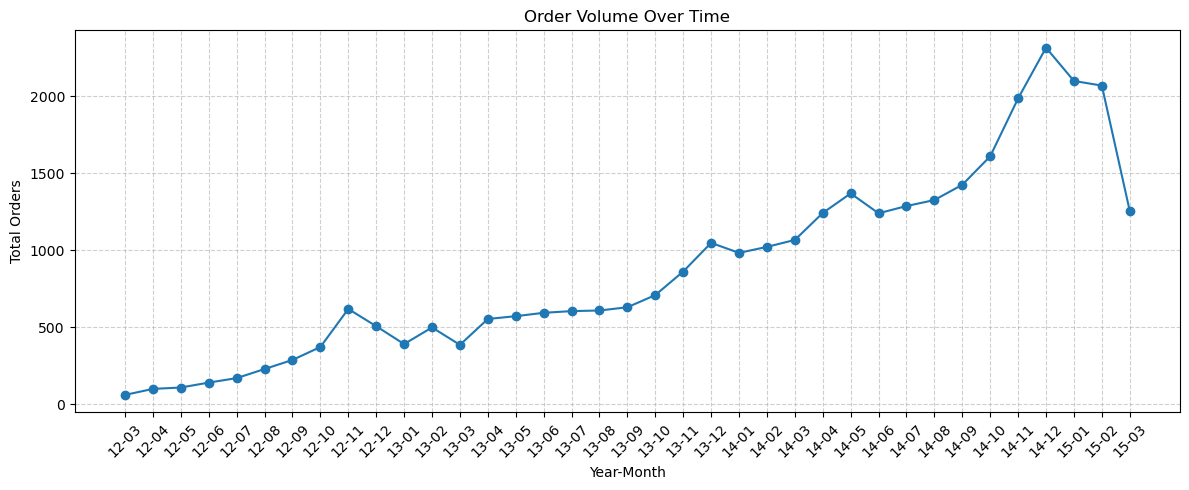

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(monthly_summary['year_month'], monthly_summary['total_orders'], marker='o', color='#1f77b4')
plt.title('Order Volume Over Time')
plt.xlabel('Year-Month')
plt.ylabel('Total Orders')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [36]:
df_order.head()

,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd,year,month,year_month,day_of_week,hour
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49,2012,2012-03,12-03,Monday,10
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49,2012,2012-03,12-03,Monday,19
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49,2012,2012-03,12-03,Tuesday,6
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49,2012,2012-03,12-03,Tuesday,9
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49,2012,2012-03,12-03,Tuesday,11


In [37]:
# Calculate Gross Profit and Profit Margin
df_order['gross_profit'] = df_order['price_usd'] - df_order['cogs_usd']
df_order['margin_pct'] = (df_order['gross_profit'] / df_order['price_usd']) * 100

# Overall Financial Summary
financial_summary = pd.DataFrame({
    'Total Revenue ($)': [df_order['price_usd'].sum()],
    'Total COGS ($)': [df_order['cogs_usd'].sum()],
    'Total Profit ($)': [df_order['gross_profit'].sum()],
    'Overall Margin (%)': [(df_order['gross_profit'].sum() / df_order['price_usd'].sum()) * 100],
    'AOV (Avg Order Value)': [df_order['price_usd'].mean()]
})

financial_summary.round(2)

,Total Revenue ($),Total COGS ($),Total Profit ($),Overall Margin (%),AOV (Avg Order Value)
0,1938509.75,722370.25,1216139.5,62.74,59.99


In [38]:

product_performance = df_order.groupby('primary_product_id').agg(
    total_orders=('order_id', 'count'),
    total_revenue=('price_usd', 'sum'),
    total_profit=('gross_profit', 'sum'),
    avg_price=('price_usd', 'mean'),
    avg_items_per_order=('items_purchased', 'mean')
).reset_index()

# Profit margin per product
product_performance['profit_margin_%'] = (
    (product_performance['total_profit'] / product_performance['total_revenue']) * 100
).round(2)

product_performance.sort_values(by='total_revenue', ascending=False)


,primary_product_id,total_orders,total_revenue,total_profit,avg_price,avg_items_per_order,profit_margin_%
0,1,23861,1419767.82,879952.0,59.501606,1.241272,61.98
1,2,4803,318109.18,200348.0,66.231351,1.183011,62.98
2,3,3068,180857.03,122410.5,58.949488,1.335398,67.68
3,4,581,19775.72,13429.0,34.037384,1.080895,67.91


In [39]:
basket_analysis = df_order.groupby('items_purchased').agg(
    order_count=('order_id', 'count'),
    total_revenue=('price_usd', 'sum'),
    avg_revenue_per_order=('price_usd', 'mean')
).reset_index()

# Percentage share of single vs multi-item orders
basket_analysis['order_share_%'] = (
    (basket_analysis['order_count'] / df_order['order_id'].count()) * 100
).round(2)

basket_analysis

,items_purchased,order_count,total_revenue,avg_revenue_per_order,order_share_%
0,1,24601,1250207.99,50.819397,76.13
1,2,7712,688301.76,89.250747,23.87


In [40]:
user_orders = df_order.groupby('user_id').agg(
    order_count=('order_id', 'nunique'),
    total_spent=('price_usd', 'sum')
).reset_index()

# Repeat order distribution
user_summary = user_orders['order_count'].value_counts().reset_index()
user_summary.columns = ['orders_per_user', 'user_count']
user_summary['pct_users'] = ((user_summary['user_count'] / user_orders.shape[0]) * 100).round(2)

user_summary

,orders_per_user,user_count,pct_users
0,1,31105,98.14
1,2,565,1.78
2,3,26,0.08


In [41]:
session_check = df_order.groupby('website_session_id').agg(
    orders_in_session=('order_id', 'nunique'),
    unique_users=('user_id', 'nunique'),
    total_spent=('price_usd', 'sum')
).reset_index()

# Check multi-order sessions
session_check.head()

,website_session_id,orders_in_session,unique_users,total_spent
0,20,1,1,49.99
1,104,1,1,49.99
2,147,1,1,49.99
3,160,1,1,49.99
4,177,1,1,49.99


In [42]:
df_order['items_purchased'].value_counts().sort_index()

items_purchased
1    24601
2     7712
Name: count, dtype: int64

In [43]:
one_item_orders = (df_order['items_purchased'] == 1).sum()

total_orders = len(df_order)

print("One-item orders:", one_item_orders)
print("Percentage:", round(one_item_orders / total_orders * 100, 2), "%")

One-item orders: 24601
Percentage: 76.13 %


business insights

Bro, the monthly data shows a clear upward trend in sales from December 2012 to December 2014. 
Monthly orders increased from 60 to 2,314, while revenue rose from $2,999 to $144,823,
indicating substantial business growth. The average order value also increased from around $49.99 
in 2012 to approximately $63–65 in 2014, suggesting customers were spending more per order. 
Sales peaked in December 2014, followed by a decline in January and February 2015. 
March 2015 also shows lower sales, but the month may be incomplete, so it should not be directly
compared with full months. Overall, the business experienced strong growth in order volume and
revenue, while average order value increased more moderately over time.


The order analysis shows that the business generated approximately $1.94 million in revenue,
with a gross profit of $1.22 million and a profit margin of 62.74%. Product 1 was the primary sales 
driver, accounting for around 74% of total orders, while Products 3 and 4 demonstrated 
relatively high profit margins. Basket-size analysis revealed that 76.13% of orders contained
one item, whereas orders containing two items had a higher average order value 
($89.25 compared with $50.82), highlighting an opportunity to increase revenue through 
cross-selling and product bundling. Customer retention was a significant weakness,
as 98.14% of customers made only one purchase, indicating limited repeat-purchase activity. 
    Additionally, order volumes increased over time, suggesting business growth,
while hourly and daily purchasing patterns could help optimize marketing efforts.
Overall, the findings suggest that the business should focus on improving customer retention,
increasing average order value, promoting profitable products, 
and using purchasing trends to guide marketing and sales strategies.


massla number2

Why monthly sales and refund figures appear inconsistent.
monthly sales collpse in 2014 while refund remain high , 


monthly sales and refund differ due to product 1 it was prduct one whose refund spiked in 2014

revenue and profit totally differ across my anlysis
revenue and profit differ because they are two different things ,
they can differ and they had to differ

In [44]:
# 1. Load refunds table
df_refunds = pd.read_csv('order_item_refunds.csv')

# 2. Join orders with refunds
df_merged = df_order.merge(df_refunds, on='order_id', how='left', suffixes=('_order', '_refund'))

# 3. Calculate cohort order month (created_at_order use karein)
df_merged['order_month'] = df_merged['created_at_order'].dt.to_period('M')

# 4. Summarize orders vs refunds by order month
cohort_refunds = df_merged.groupby('order_month').agg(
    total_orders=('order_id', 'nunique'),
    total_refunds=('order_item_refund_id', 'count')
).reset_index()

cohort_refunds['refund_rate_%'] = (cohort_refunds['total_refunds'] / cohort_refunds['total_orders']) * 100
cohort_refunds

,order_month,total_orders,total_refunds,refund_rate_%
0,2012-03,60,1,1.666667
1,2012-04,99,5,5.050505
2,2012-05,108,4,3.703704
3,2012-06,140,8,5.714286
4,2012-07,169,14,8.284024
5,2012-08,228,17,7.456140
6,2012-09,287,26,9.059233
7,2012-10,371,27,7.277628
8,2012-11,618,46,7.443366
9,2012-12,506,30,5.928854


In [45]:
# Check refund rate by product for Aug-Sep 2014
df_merged['order_month_str'] = df_merged['order_month'].astype(str)
aug_sep_data = df_merged[df_merged['order_month_str'].isin(['2014-08', '2014-09'])]

aug_sep_data.groupby(['order_month_str', 'primary_product_id']).agg(
    total_orders=('order_id', 'nunique'),
    total_refunds=('order_item_refund_id', 'count')
).assign(
    refund_rate=lambda x: (x['total_refunds'] / x['total_orders']) * 100
)

total_orders  total_refunds  refund_rate
order_month_str primary_product_id                                          
2014-08         1                            939            139    14.802982
                2                            189              3     1.587302
                3                            197             16     8.121827
2014-09         1                           1040            151    14.519231
                2                            199             10     5.025126
                3                            185             12     6.486486

### Refund Rate Analysis — Key Findings

* **Monthly refund trends:** August 2014 (11.92%) and September 2014 (12.15%) had unusually high refund rates, followed by a sharp decline to 3.67% in October.
* **Product-level analysis:** Product 1 had the highest refund rates in both August (14.80%) and September (14.52%), considerably higher than Products 2 and 3.
* **Business insight:** Product 1's elevated refund rate makes it a priority for further investigation, although it does not necessarily indicate a product-quality problem.
* **Remaining issue:** The monthly order and refund counts help investigate earlier inconsistencies, but refund timing and monthly refunded amounts still need validation before drawing firm conclusions about sales and refund trends.


The business appears to generate substantial gross profit from product sales, with Product 1 (the Original Mr. Fuzzy) serving as its core product. Over time, the business expanded its catalog with additional products and developed opportunities to increase revenue through cross-selling.
Our analysis also revealed data-quality issues that matter for business decisions. Before making final product-level recommendations, we need to reconcile the order_items data and validate the relationships between orders, individual items, and refunds.

In [46]:

import pandas as pd


df_order_item=pd.read_csv('order_items.csv')
print("Rows and columns:", df_order_item.shape)
print("First date:", df_order_item["created_at"].min())
print("Last date:", df_order_item["created_at"].max())
print("Unique order IDs:", df_order_item["order_id"].nunique())

Rows and columns: (40025, 7)
First date: 2012-03-19 10:42:46
Last date: 2015-03-19 05:38:31
Unique order IDs: 32313


In [47]:
print(df_order_item.columns.tolist())
print(df_order_item.tail(10))

['order_item_id', 'created_at', 'order_id', 'product_id', 'is_primary_item', 'price_usd', 'cogs_usd']
       order_item_id           created_at  order_id  product_id  \
40015          40016  2015-03-19 01:04:35     32305           1   
40016          40017  2015-03-19 01:42:17     32306           4   
40017          40018  2015-03-19 01:51:39     32307           3   
40018          40019  2015-03-19 02:11:42     32308           1   
40019          40020  2015-03-19 03:58:12     32309           1   
40020          40021  2015-03-19 04:10:43     32310           4   
40021          40022  2015-03-19 05:27:28     32311           2   
40022          40023  2015-03-19 05:27:28     32311           4   
40023          40024  2015-03-19 05:35:57     32312           4   
40024          40025  2015-03-19 05:38:31     32313           1   

       is_primary_item  price_usd  cogs_usd  
40015                1      49.99     19.49  
40016                1      29.99      9.49  
40017                1

In [48]:
refunds= df_item_refund=pd.read_csv('order_item_refunds.csv')





rfunds

In [49]:


print('rows and columns:', refunds.shape)
print('columns:',refunds.columns.tolist())

print( refunds.head())

rows and columns: (1731, 5)
columns: ['order_item_refund_id', 'created_at', 'order_item_id', 'order_id', 'refund_amount_usd']
   order_item_refund_id           created_at  order_item_id  order_id  \
0                     1  2012-04-06 11:32:43             57        57   
1                     2  2012-04-13 01:09:43             74        74   
2                     3  2012-04-15 07:03:48             71        71   
3                     4  2012-04-17 20:00:37            118       118   
4                     5  2012-04-22 20:53:49            116       116   

   refund_amount_usd  
0              49.99  
1              49.99  
2              49.99  
3              49.99  
4              49.99  


In [50]:

print("Data types:")
print(refunds.dtypes)

print("\nMissing values:")
print(refunds.isnull().sum())

print("\nDuplicate refund IDs:",
      refunds["order_item_refund_id"].duplicated().sum())

print("Duplicate order-item IDs:",
      refunds["order_item_id"].duplicated().sum())

print("Duplicate order IDs:",
      refunds["order_id"].duplicated().sum())

print("\nRefund date range:")
print("First:", refunds["created_at"].min())
print("Last:", refunds["created_at"].max())


Data types:
order_item_refund_id      int64
created_at               object
order_item_id             int64
order_id                  int64
refund_amount_usd       float64
dtype: object

Missing values:
order_item_refund_id    0
created_at              0
order_item_id           0
order_id                0
refund_amount_usd       0
dtype: int64

Duplicate refund IDs: 0
Duplicate order-item IDs: 0
Duplicate order IDs: 8

Refund date range:
First: 2012-04-06 11:32:43
Last: 2015-04-01 18:11:08


In [51]:

refunds_per_order = (
    refunds.groupby("order_id")
    .size()
    .reset_index(name="refund_records")
)

multiple_refunds = refunds_per_order[
    refunds_per_order["refund_records"] > 1
].sort_values("refund_records", ascending=False)

print("Orders with multiple refund records:",
      len(multiple_refunds))

print("\nOrders and their refund-record counts:")
print(multiple_refunds.to_string(index=False))


Orders with multiple refund records: 8

Orders and their refund-record counts:
 order_id  refund_records
     9324               2
    19518               2
    19848               2
    23321               2
    24472               2
    27061               2
    28802               2
    31486               2


In [52]:

order_items = pd.read_csv(
    r"C:\Users\wedne\Downloads\Maven+Fuzzy+Factory\order_items.csv"
)

print("Order items shape:", order_items.shape)
print("Unique order_item_id values:",
      order_items["order_item_id"].nunique())

print("Duplicate order_item_id values:",
      order_items["order_item_id"].duplicated().sum())


Order items shape: (40025, 7)
Unique order_item_id values: 40025
Duplicate order_item_id values: 0


In [53]:
df_order_item=pd.read_csv('order_items.csv')
shappe= df_order_item.shape
uniqe= df_order_item['order_item_id'].unique()
duplicted= df_order_item['order_item_id'].duplicated().sum()

print(shappe)
print(uniqe)
print(duplicted)

(40025, 7)
[    1     2     3 ... 40023 40024 40025]
0


In [54]:

matched = refunds.merge(
    order_items[["order_item_id", "order_id", "product_id",
                 "price_usd", "cogs_usd"]],
    on="order_item_id",
    how="left",
    suffixes=("_refund", "_item"),
    indicator=True
)

print("Total refund records:", len(matched))
print("\nMatch status:")
print(matched["_merge"].value_counts())

print("\nOrder ID mismatches:",
      (matched["order_id_refund"] != matched["order_id_item"]).sum())

print("\nUnmatched refund records:")
print(
    matched.loc[
        matched["_merge"] == "left_only",
        ["order_item_refund_id", "order_item_id", "order_id_refund"]
    ].to_string(index=False)
)


Total refund records: 1731

Match status:
_merge
both          1731
left_only        0
right_only       0
Name: count, dtype: int64

Order ID mismatches: 0

Unmatched refund records:
Empty DataFrame
Columns: [order_item_refund_id, order_item_id, order_id_refund]
Index: []


In [55]:

print("Refund amount summary:")
print(refunds["refund_amount_usd"].describe())

print("\nRefund amounts equal to or below zero:",
      (refunds["refund_amount_usd"] <= 0).sum())

print("\nRefund amount vs. item price:")

matched["amount_difference"] = (
    matched["refund_amount_usd"] - matched["price_usd"]
)

print("Refunds greater than item price:",
      (matched["refund_amount_usd"] > matched["price_usd"]).sum())

print("Refunds equal to item price:",
      (matched["refund_amount_usd"] == matched["price_usd"]).sum())

print("Refunds below item price:",
      (matched["refund_amount_usd"] < matched["price_usd"]).sum())


Refund amount summary:
count    1731.000000
mean       49.300225
std         4.956015
min        29.990000
25%        49.990000
50%        49.990000
75%        49.990000
max        59.990000
Name: refund_amount_usd, dtype: float64

Refund amounts equal to or below zero: 0

Refund amount vs. item price:
Refunds greater than item price: 0
Refunds equal to item price: 1731
Refunds below item price: 0


In [56]:
order_items['created_at']=pd.to_datetime(order_items['created_at'])
refunds['created_at']=pd.to_datetime(order_items['created_at'])

print('order_items date_range:')
print(order_items['created_at'].min(), 'to',
      order_items['created_at'].max())

print('refunds date_range:')
print(refunds['created_at'].min(),'to',
      refunds['created_at'].max())

order_items date_range:
2012-03-19 10:42:46 to 2015-03-19 05:38:31
refunds date_range:
2012-03-19 10:42:46 to 2012-11-21 14:35:15


In [57]:

print("Refunds data type:")
print(refunds["created_at"].dtype)

print("\nFirst 5 refund records:")
print(refunds[["order_item_refund_id", "created_at"]].head())

print("\nLast 10 refund records:")
print(refunds[["order_item_refund_id", "created_at"]].tail(10))

print("\nEarliest 5 dates:")
print(refunds["created_at"].sort_values().head().to_list())

print("\nLatest 5 dates:")
print(refunds["created_at"].sort_values().tail().to_list())


Refunds data type:
datetime64[ns]

First 5 refund records:
   order_item_refund_id          created_at
0                     1 2012-03-19 10:42:46
1                     2 2012-03-19 19:27:37
2                     3 2012-03-20 06:44:45
3                     4 2012-03-20 09:41:45
4                     5 2012-03-20 11:28:15

Last 10 refund records:
      order_item_refund_id          created_at
1721                  1722 2012-11-20 19:43:19
1722                  1723 2012-11-21 04:50:53
1723                  1724 2012-11-21 08:46:51
1724                  1725 2012-11-21 09:23:11
1725                  1726 2012-11-21 11:47:09
1726                  1727 2012-11-21 12:26:47
1727                  1728 2012-11-21 12:40:43
1728                  1729 2012-11-21 12:41:15
1729                  1730 2012-11-21 14:05:48
1730                  1731 2012-11-21 14:35:15

Earliest 5 dates:
[Timestamp('2012-03-19 10:42:46'), Timestamp('2012-03-19 19:27:37'), Timestamp('2012-03-20 06:44:45'), Timestamp('20

In [58]:

refunds_check = pd.read_csv(
    r"C:\Users\wedne\Downloads\Maven+Fuzzy+Factory\order_item_refunds.csv"
)

print("Shape:", refunds_check.shape)
print("\nFirst 5 records:")
print(refunds_check.head())

print("\nLast 5 records:")
print(refunds_check.tail())

print("\nOriginal date range:")
print(refunds_check["created_at"].min())
print(refunds_check["created_at"].max())


Shape: (1731, 5)

First 5 records:
   order_item_refund_id           created_at  order_item_id  order_id  \
0                     1  2012-04-06 11:32:43             57        57   
1                     2  2012-04-13 01:09:43             74        74   
2                     3  2012-04-15 07:03:48             71        71   
3                     4  2012-04-17 20:00:37            118       118   
4                     5  2012-04-22 20:53:49            116       116   

   refund_amount_usd  
0              49.99  
1              49.99  
2              49.99  
3              49.99  
4              49.99  

Last 5 records:
      order_item_refund_id           created_at  order_item_id  order_id  \
1726                  1727  2015-03-30 09:37:23          39950     32255   
1727                  1728  2015-03-30 21:33:51          39671     32049   
1728                  1729  2015-03-31 19:59:48          39729     32090   
1729                  1730  2015-04-01 03:54:48          39717     

In [59]:

refunds_check["created_at"] = pd.to_datetime(
    refunds_check["created_at"]
)

print("Refund date range:",
      refunds_check["created_at"].min(),
      "to",
      refunds_check["created_at"].max())

print("\nRefund records by year:")
print(refunds_check["created_at"].dt.year.value_counts().sort_index())

print("\nRefund records in August 2014:",
      ((refunds_check["created_at"] >= "2014-08-01") &
       (refunds_check["created_at"] < "2014-09-01")).sum())

print("Refund records in September 2014:",
      ((refunds_check["created_at"] >= "2014-09-01") &
       (refunds_check["created_at"] < "2014-10-01")).sum())


Refund date range: 2012-04-06 11:32:43 to 2015-04-01 18:11:08

Refund records by year:
created_at
2012    169
2013    339
2014    960
2015    263
Name: count, dtype: int64

Refund records in August 2014: 93
Refund records in September 2014: 237


In [60]:

# One row per order, with its order date
orders_monthly = (
    order_items.groupby("order_id", as_index=False)
    .agg(order_date=("created_at", "min"))
)

# Orders with at least one refund
refunded_order_ids = refunds_check["order_id"].unique()

orders_monthly["was_refunded"] = (
    orders_monthly["order_id"].isin(refunded_order_ids)
)

orders_monthly["month"] = (
    orders_monthly["order_date"].dt.to_period("M")
)

monthly_refund_rates = (
    orders_monthly.groupby("month")
    .agg(
        total_orders=("order_id", "nunique"),
        refunded_orders=("was_refunded", "sum")
    )
)

monthly_refund_rates["refund_rate_pct"] = (
    monthly_refund_rates["refunded_orders"]
    / monthly_refund_rates["total_orders"] * 100
)

print(
    monthly_refund_rates.loc["2014-07":"2014-10"]
    .round(2)
)


         total_orders  refunded_orders  refund_rate_pct
month                                                  
2014-07          1286               66             5.13
2014-08          1325              157            11.85
2014-09          1424              172            12.08
2014-10          1609               59             3.67


In [61]:

# Select items from orders placed in August and September 2014
items_period = order_items[
    order_items["created_at"].dt.to_period("M").isin(
        ["2014-08", "2014-09"]
    )
].copy()

# Mark whether each item was refunded
refunded_item_ids = set(refunds_check["order_item_id"])

items_period["was_refunded"] = (
    items_period["order_item_id"].isin(refunded_item_ids)
)

items_period["month"] = (
    items_period["created_at"].dt.to_period("M")
)

product_refund_rates = (
    items_period.groupby(["month", "product_id"])
    .agg(
        total_items=("order_item_id", "nunique"),
        refunded_items=("was_refunded", "sum")
    )
)

product_refund_rates["refund_rate_pct"] = (
    product_refund_rates["refunded_items"]
    / product_refund_rates["total_items"] * 100
)

print(product_refund_rates.round(2).to_string())


Empty DataFrame
Columns: [total_items, refunded_items, refund_rate_pct]
Index: []


In [62]:

print("Order-item date dtype:", order_items["created_at"].dtype)

print("\nOrder-item date range:")
print(order_items["created_at"].min())
print(order_items["created_at"].max())

print("\nOrders by year:")
print(order_items["created_at"].dt.year.value_counts().sort_index())

print("\nRecords in August 2014:",
      (order_items["created_at"].dt.strftime("%Y-%m") == "2014-08").sum())

print("Records in September 2014:",
      (order_items["created_at"].dt.strftime("%Y-%m") == "2014-09").sum())


Order-item date dtype: datetime64[ns]

Order-item date range:
2012-03-19 10:42:46
2015-03-19 05:38:31

Orders by year:
created_at
2012     2586
2013     7613
2014    22581
2015     7245
Name: count, dtype: int64

Records in August 2014: 1792
Records in September 2014: 1951


In [63]:

items_period = order_items[
    order_items["created_at"].dt.strftime("%Y-%m").isin(
        ["2014-08", "2014-09"]
    )
].copy()

print("Filtered shape:", items_period.shape)

print("\nItems by month and product:")
print(
    items_period.groupby([
        items_period["created_at"].dt.strftime("%Y-%m"),
        "product_id"
    ]).size().to_string()
)


Filtered shape: (3743, 7)

Items by month and product:
created_at  product_id
2014-08     1              958
            2              237
            3              294
            4              303
2014-09     1             1056
            2              251
            3              317
            4              327


In [64]:

refunded_item_ids = set(refunds_check["order_item_id"])

items_period["was_refunded"] = (
    items_period["order_item_id"].isin(refunded_item_ids)
)

items_period["month"] = (
    items_period["created_at"].dt.strftime("%Y-%m")
)

product_refund_rates = (
    items_period.groupby(["month", "product_id"])
    .agg(
        total_items=("order_item_id", "nunique"),
        refunded_items=("was_refunded", "sum")
    )
)

product_refund_rates["refund_rate_pct"] = (
    product_refund_rates["refunded_items"]
    / product_refund_rates["total_items"] * 100
)

print(product_refund_rates.round(2).to_string())


                    total_items  refunded_items  refund_rate_pct
month   product_id                                              
2014-08 1                   958             132            13.78
        2                   237               4             1.69
        3                   294              20             6.80
        4                   303               2             0.66
2014-09 1                  1056             140            13.26
        2                   251               8             3.19
        3                   317              21             6.62
        4                   327               4             1.22


In [65]:

items_window = order_items[
    (order_items["created_at"] >= "2014-07-01") &
    (order_items["created_at"] < "2014-11-01") &
    (order_items["product_id"] == 1)
].copy()

items_window["was_refunded"] = (
    items_window["order_item_id"].isin(refunded_item_ids)
)

items_window["month"] = (
    items_window["created_at"].dt.strftime("%Y-%m")
)

product1_monthly = (
    items_window.groupby("month")
    .agg(
        total_items=("order_item_id", "nunique"),
        refunded_items=("was_refunded", "sum")
    )
)

product1_monthly["refund_rate_pct"] = (
    product1_monthly["refunded_items"]
    / product1_monthly["total_items"] * 100
)

print(product1_monthly.round(2))


         total_items  refunded_items  refund_rate_pct
month                                                
2014-07          961              42             4.37
2014-08          958             132            13.78
2014-09         1056             140            13.26
2014-10         1173              29             2.47


In [66]:

items_window_all = order_items[
    (order_items["created_at"] >= "2014-07-01") &
    (order_items["created_at"] < "2014-11-01")
].copy()

items_window_all["was_refunded"] = (
    items_window_all["order_item_id"].isin(refunded_item_ids)
)

items_window_all["month"] = (
    items_window_all["created_at"].dt.strftime("%Y-%m")
)

all_products_monthly = (
    items_window_all.groupby("month")
    .agg(
        total_items=("order_item_id", "nunique"),
        refunded_items=("was_refunded", "sum")
    )
)

all_products_monthly["refund_rate_pct"] = (
    all_products_monthly["refunded_items"]
    / all_products_monthly["total_items"] * 100
)

print(all_products_monthly.round(2))


         total_items  refunded_items  refund_rate_pct
month                                                
2014-07         1745              66             3.78
2014-08         1792             158             8.82
2014-09         1951             173             8.87
2014-10         2202              59             2.68


Business interpretation
- The item refund rate increased from 3.78% in July to 8.82% in August.
- September remained elevated at 8.87%, despite higher item sales.
- October's rate fell to 2.68%, even though sales volume reached its highest level in this four-month period.
August and September show a temporary period of elevated refunds. October's decline suggests the problem may have been temporary rather than a persistent relationship between sales volume and refunds.
These are retrospective rates by purchase month, not the proportion of refunds processed in each calendar month.

Business interpretation
Product 1's refund rate rose from 4.37% in July to 13.78% in August, remained high in September, and then fell to 2.47% in October.
The movement closely follows the overall item refund pattern. That makes Product 1 a strong candidate for further investigation.
Potential explanations include product-quality problems, fulfillment issues, or a temporary change in the customer experience. Our current data cannot distinguish among these possibilities.

finalizing financial metrices

In [67]:
orders = pd.read_csv(
    r"C:\Users\wedne\Downloads\Maven+Fuzzy+Factory\orders.csv"
)

print("Shape:", orders.shape)
print("\nColumns:")
print(orders.columns.tolist())
print("\nFirst 5 rows:")
display(orders.head())

Shape: (32313, 8)

Columns:
['order_id', 'created_at', 'website_session_id', 'user_id', 'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd']

First 5 rows:


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49


In [68]:
print("Unique order IDs:", orders["order_id"].nunique())
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Missing values:\n", orders[["price_usd", "cogs_usd"]].isna().sum())

print("\nFinancial totals:")
print("Revenue: $", round(orders["price_usd"].sum(), 2))
print("COGS: $", round(orders["cogs_usd"].sum(), 2))
print("Gross profit: $", round(
    (orders["price_usd"] - orders["cogs_usd"]).sum(), 2
))
print("Average order value: $", round(orders["price_usd"].mean(), 2))

Unique order IDs: 32313
Duplicate order IDs: 0
Missing values:
 price_usd    0
cogs_usd     0
dtype: int64

Financial totals:
Revenue: $ 1938509.75
COGS: $ 722370.25
Gross profit: $ 1216139.5
Average order value: $ 59.99


Business interpretation: For every $100 in recorded revenue, approximately $62.74 remains after subtracting COGS. This is gross profit, not net profit, because operating expenses, marketing costs, salaries, and other overheads have not been deducted.

In [69]:
print("ORDER-LEVEL TOTALS")
print("Revenue:", round(orders["price_usd"].sum(), 2))
print("COGS:", round(orders["cogs_usd"].sum(), 2))

print("\nITEM-LEVEL TOTALS")
print("Item rows:", len(order_items))
print("Unique orders:", order_items["order_id"].nunique())
print("Revenue:", round(order_items["price_usd"].sum(), 2))
print("COGS:", round(order_items["cogs_usd"].sum(), 2))

ORDER-LEVEL TOTALS
Revenue: 1938509.75
COGS: 722370.25

ITEM-LEVEL TOTALS
Item rows: 40025
Unique orders: 32313
Revenue: 1938509.75
COGS: 722370.25


In [70]:
print("Gross profit margin (%):",
      round(
          (orders["price_usd"].sum() - orders["cogs_usd"].sum())
          / orders["price_usd"].sum() * 100, 2
      ))

print("\nItems per order:")
print(order_items.groupby("order_id").size().value_counts().sort_index())

Gross profit margin (%): 62.74

Items per order:
1    24601
2     7712
Name: count, dtype: int64


Bro, here is the final business interpretation of the financial metrics from our Maven Fuzzy Factory project. This is the business analysis we can record before moving to visualizations.

## 1. Financial performance summary

| Metric                       | Result        |
| ---------------------------- | ------------- |
| Total orders                 | 32,313        |
| Total revenue                | $1,938,509.75 |
| Cost of goods sold (COGS)    | $722,370.25   |
| Gross profit                 | $1,216,139.50 |
| Gross profit margin          | 62.74%        |
| Average order value (AOV)    | $59.99        |
| Orders with one item         | 24,601        |
| Orders with two item records | 7,712         |

## 2. Business interpretation

1\. The business generated nearly $1.94 million in revenue.

Across 32,313 orders, the business recorded substantial sales activity. This provides a useful baseline for evaluating how revenue changes over time, which products perform best, and which marketing channels contribute to sales.

2\. Gross profit was approximately $1.22 million.

After deducting the $722,370.25 cost of goods sold, $1,216,139.50 remained as gross profit. This amount is available to cover other business expenses and contribute to net profit.

3\. The gross profit margin was 62.74%.

For every $100 in revenue, approximately $62.74 remained after accounting for COGS. This suggests that the recorded sales have a substantial gross-profit contribution. However, we cannot conclude that the business is highly profitable overall without examining advertising, operating, and other expenses.

4\. The average order value was $59.99.

On average, each order generated approximately $60 in revenue. This gives us a baseline for assessing whether particular products, marketing channels, or customer segments generate higher-value orders.

5\. Most orders contained one item.

Approximately 76.1% of orders had one item record, while 23.9% had two. This suggests an opportunity to investigate whether product bundles, complementary-product recommendations, or promotions could increase the number of items purchased per order. It is an opportunity to test, not proof that such strategies would increase profit.

## 3. Data validation findings

We also verified the financial figures against both original datasets.

- The `orders` dataset contains 32,313 rows and 32,313 unique order IDs.
- The `order_items` dataset contains 40,025 item records across the same 32,313 distinct orders.
- Revenue and COGS totals match exactly across both datasets.
- Neither `price_usd` nor `cogs_usd` has missing values in `orders`.

This consistency supports using these financial metrics as our project's baseline.

## 4. Overall business 

Maven Fuzzy Factory recorded approximately $1.94 million in revenue and $1.22 million in gross profit, with a 62.74% gross profit margin and an average order value of $59.99. Most orders contained a single item, creating a potential area for further investigation into increasing basket size.

These figures establish the business's overall financial position, but they do not yet explain why revenue and profit change. Our next analyses should investigate monthly revenue and profit trends, product-level performance, acquisition-channel effectiveness, the website conversion funnel, and refunds.

One important distinction: gross profit is not net profit, and the figures above are validated baseline metrics—not yet the final conclusion for the entire project.

anila phle dekho kia kia visulize krna chahia , aur kia kia visulize krne ki zroorat ha ,poora dataset tmhare saamne ha, 


products, orders, refunds, gross profit , revenue, finanacial metrices , product names, monthly order trend ,yearly, product names with sales, and which channel which website , which promotion streategy bought users to product, phir konsa product lia , phir kis product ne zyada revenue generate kray, 

visulization

In [71]:
df_web_session.head()

,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com


is main mja visulize krna ha k kis utm_source , utm_campaign , utm_content, device, aur http_refrer na zyada logon ko orders krne kitrf lead kia

In [72]:
df_merged = pd.merge(df_web_session ,df_order , on='website_session_id', how= 'left')
summary = df_merged.groupby(['utm_source','utm_campaign','utm_content','device_type'])['order_id'].count().reset_index()
print(summary.head())

  utm_source utm_campaign utm_content device_type  order_id
0    bsearch        brand      b_ad_2     desktop       677
1    bsearch        brand      b_ad_2      mobile        24
2    bsearch     nonbrand      b_ad_1     desktop      3584
3    bsearch     nonbrand      b_ad_1      mobile       234
4    gsearch        brand      g_ad_2     desktop      2100


In [73]:
print("Web session columns:", df_web_session.columns.tolist())
print("Order item columns:", df_order_item.columns.tolist())

Web session columns: ['website_session_id', 'created_at', 'user_id', 'is_repeat_session', 'utm_source', 'utm_campaign', 'utm_content', 'device_type', 'http_referer']
Order item columns: ['order_item_id', 'created_at', 'order_id', 'product_id', 'is_primary_item', 'price_usd', 'cogs_usd']


In [74]:
# Dono tables ko sahi variable names ke sath merge karein
df_merged = pd.merge(df_web_session, df_order, on='website_session_id', how='left')

# Phir orders count karne ke liye group by karein
summary = df_merged.groupby(['utm_source', 'utm_campaign', 'utm_content', 'device_type', 'http_referer'])['order_id'].count().reset_index(name='total_orders')

print(summary.head())

  utm_source utm_campaign utm_content device_type             http_referer  \
0    bsearch        brand      b_ad_2     desktop  https://www.bsearch.com   
1    bsearch        brand      b_ad_2      mobile  https://www.bsearch.com   
2    bsearch     nonbrand      b_ad_1     desktop  https://www.bsearch.com   
3    bsearch     nonbrand      b_ad_1      mobile  https://www.bsearch.com   
4    gsearch        brand      g_ad_2     desktop  https://www.gsearch.com   

   total_orders  
0           677  
1            24  
2          3584  
3           234  
4          2100  


step_2 visulization

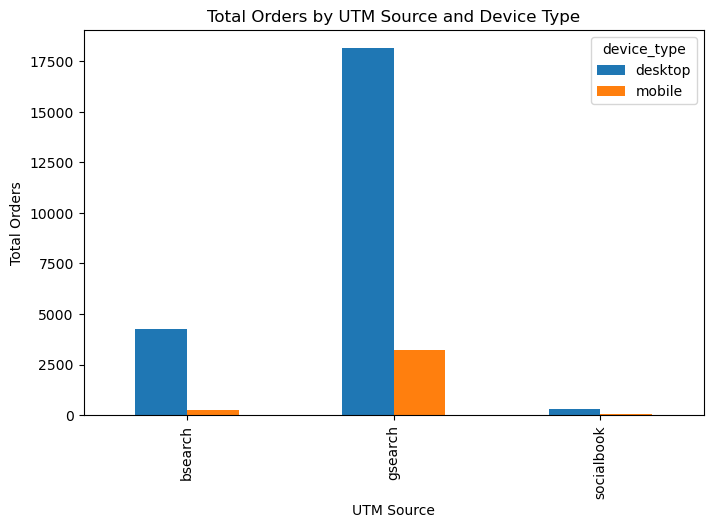

In [75]:
# Sirf main columns ko group karein taake chart saaf nazar aaye
plot_data = df_merged.groupby(['utm_source', 'device_type'])['order_id'].count().unstack()

# Ab bar plot banayein
plot_data.plot(kind='bar', figsize=(8, 5))
plt.title('Total Orders by UTM Source and Device Type')
plt.xlabel('UTM Source')
plt.ylabel('Total Orders')
plt.show()

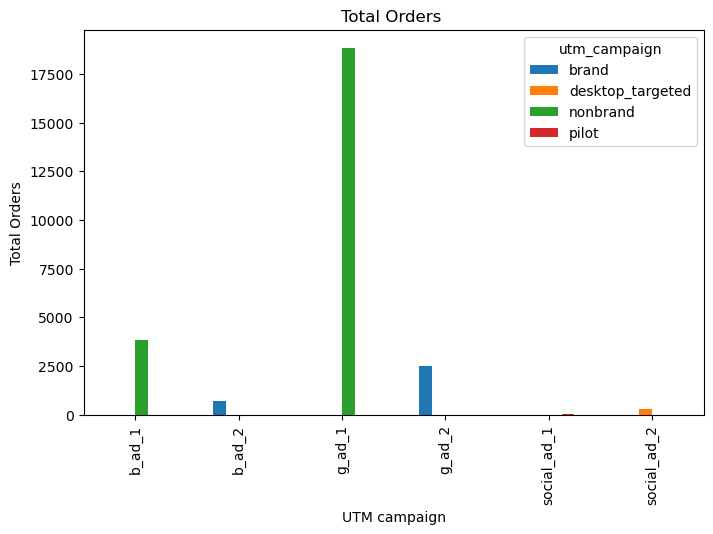

In [76]:
plot_data = df_merged.groupby(['utm_content', 'utm_campaign'])['order_id'].count().unstack()

# Ab bar plot banayein
plot_data.plot(kind='bar', figsize=(8, 5))
plt.title('Total Orders ')
plt.xlabel('UTM campaign')
plt.ylabel('Total Orders')
plt.show()

visulization 3, montly ravenue and gross profit

monthly agreegation


In [77]:
monthly_summary = df_order.groupby('year_month').agg(
    revenue= ('price_usd','sum'),
    gross_profit=('gross_profit','sum')
)

monthly_summary.head()




,revenue,gross_profit
year_month,,
12-03,2999.40,1830.0
12-04,4949.01,3019.5
12-05,5398.92,3294.0
12-06,6998.60,4270.0
12-07,8448.31,5154.5


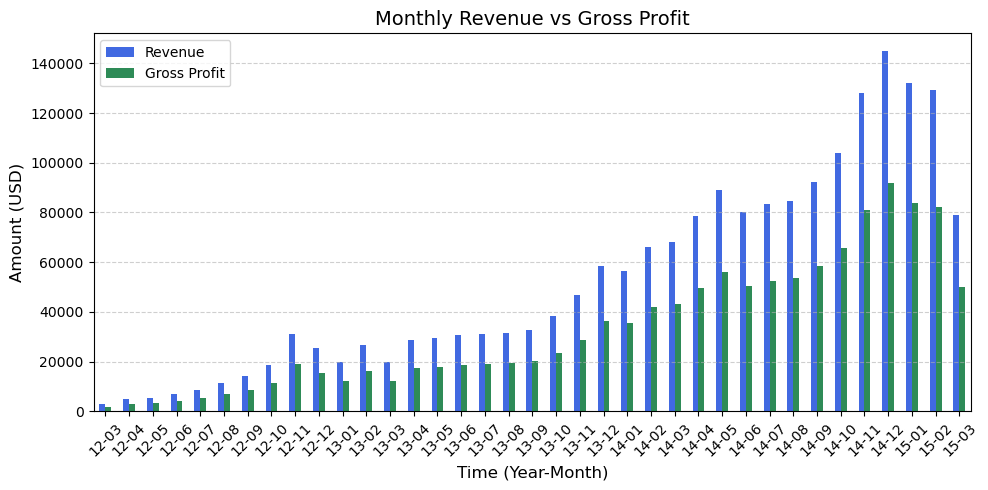

In [79]:
import matplotlib.pyplot as plt

# 1. Bar plot banayein direct dataframe se
monthly_summary.plot(kind='bar', figsize=(10, 5), color=['royalblue', 'seagreen'])

# 2. Graph ki styling
plt.title('Monthly Revenue vs Gross Profit', fontsize=14)
plt.xlabel('Time (Year-Month)', fontsize=12)
plt.ylabel('Amount (USD)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(['Revenue', 'Gross Profit'])
plt.tight_layout()

plt.show()

revenue start main bht thora tha 2013 ka baad increase hona start hwa , 2014, main apnii peak pr tha lakin us k baad phir thora hogya, 

product_wise revenue and gross profit

In [80]:
df_product_sales = pd.merge(
    df_order_item,
    df_product[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

product_wise = df_product_sales.groupby('product_name').agg(
    total_items=('order_item_id', 'count'),
    revenue=('price_usd', 'sum'),
    cogs=('cogs_usd', 'sum')
)

product_wise['gross_profit'] = product_wise['revenue'] - product_wise['cogs']

product_wise = product_wise.sort_values('revenue', ascending=False)

product_wise

,total_items,revenue,cogs,gross_profit
product_name,,,,
The Original Mr. Fuzzy,24226,1211057.74,472164.74,738893.0
The Forever Love Bear,5796,347702.04,130352.04,217350.0
The Birthday Sugar Panda,4985,229260.15,72232.65,157027.5
The Hudson River Mini bear,5018,150489.82,47620.82,102869.0


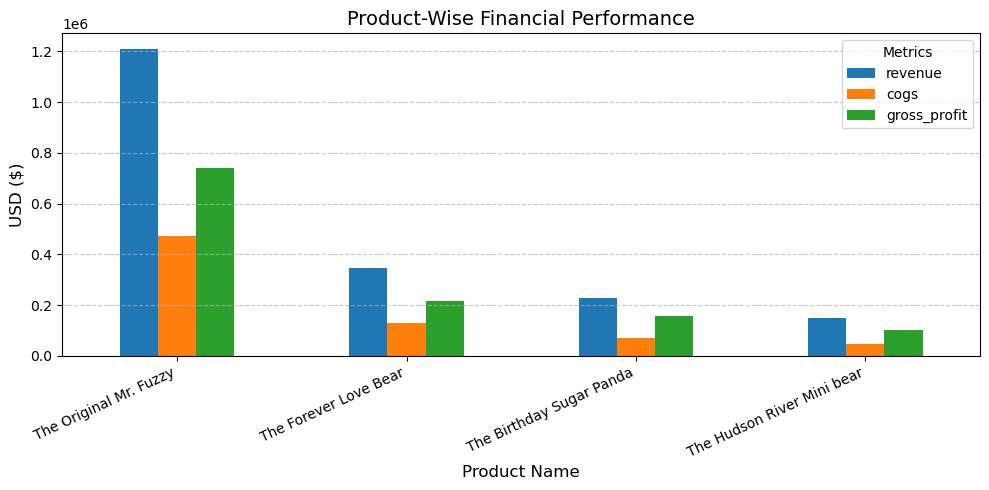

In [81]:
import matplotlib.pyplot as plt

# Sirf financial metrics ko plot karein (total_items ko chor kar)
product_wise[['revenue', 'cogs', 'gross_profit']].plot(
    kind='bar', figsize=(10, 5), color=['#1f77b4', '#ff7f0e', '#2ca02c']
)

plt.title('Product-Wise Financial Performance', fontsize=14)
plt.xlabel('Product Name', fontsize=12)
plt.ylabel('USD ($)', fontsize=12)
plt.xticks(rotation=25, ha='right')
plt.legend(title='Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Business question: Kaun se acquisition channels zyada sessions aur orders laate hain?
- X-axis: Marketing source/campaign
- Y-axis: Orders, with conversion rate as a separate measure
- Dataset: website_sessions + orders

In [82]:
print(df_order.columns)
print(df_web_session.columns)

Index(['order_id', 'created_at', 'website_session_id', 'user_id',
       'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd',
       'year', 'month', 'year_month', 'day_of_week', 'hour', 'gross_profit',
       'margin_pct'],
      dtype='object')
Index(['website_session_id', 'created_at', 'user_id', 'is_repeat_session',
       'utm_source', 'utm_campaign', 'utm_content', 'device_type',
       'http_referer'],
      dtype='object')


In [83]:
# Sirf website_session_id ko match karein order table se
merging = pd.merge(
    df_web_session,
    df_order[['website_session_id', 'order_id']],  # order_id utha lein order table se
    on='website_session_id',
    how='left'
)

# Ab groupby kar ke sessions aur orders count kar lein
acquisition_channel = merging.groupby(['utm_source', 'utm_campaign']).agg(
    total_sessions=('website_session_id', 'count'),
    total_orders=('order_id', 'count')  # order_id se pata chalega kitne orders hue
)

print(acquisition_channel)

                             total_sessions  total_orders
utm_source utm_campaign                                  
bsearch    brand                       7914           701
           nonbrand                   54909          3818
gsearch    brand                      33329          2511
           nonbrand                  282706         18822
socialbook desktop_targeted            5590           288
           pilot                       5095            55


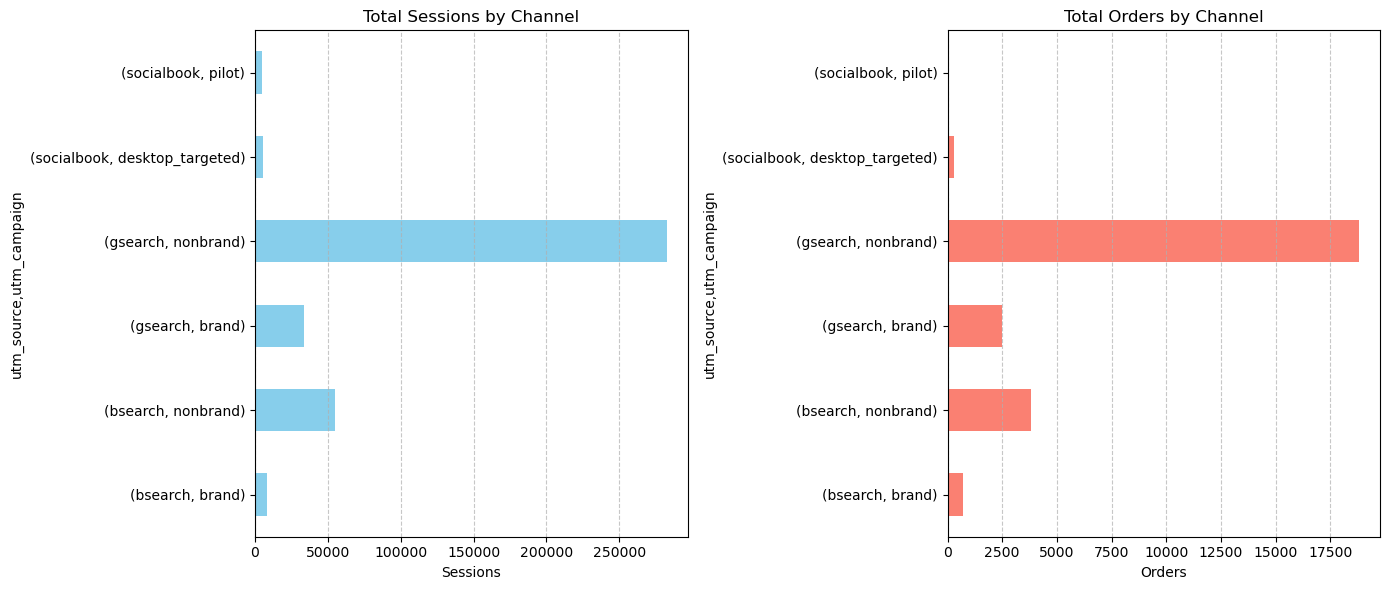

In [85]:
import matplotlib.pyplot as plt

# Dono metrics ke liye alag subplots banayein
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left side: Total Sessions
acquisition_channel['total_sessions'].plot(kind='barh', ax=axes[0], color='skyblue')
axes[0].set_title('Total Sessions by Channel')
axes[0].set_xlabel('Sessions')
axes[0].grid(axis='x', linestyle='--', alpha=0.7)

# Right side: Total Orders
acquisition_channel['total_orders'].plot(kind='barh', ax=axes[1], color='salmon')
axes[1].set_title('Total Orders by Channel')
axes[1].set_xlabel('Orders')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Business question: Kis product ka refund rate comparatively high hai?
- X-axis: Product
- Y-axis: Percentage of items refunded
- Dataset: order_items + order_item_refunds + products

refund ,rate, , refunds aue product

In [87]:
df_item_refund.head()

,order_item_refund_id,created_at,order_item_id,order_id,refund_amount_usd
0,1,2012-03-19 10:42:46,57,57,49.99
1,2,2012-03-19 19:27:37,74,74,49.99
2,3,2012-03-20 06:44:45,71,71,49.99
3,4,2012-03-20 09:41:45,118,118,49.99
4,5,2012-03-20 11:28:15,116,116,49.99


In [88]:
df_product.head()

,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda
3,4,2014-02-05 10:00:00,The Hudson River Mini bear


Total Items vs Refunded Items Count:

Har product ke total sold items count kar lein (e.g., count() ya sum() of quantity/items).

Har product ke total refunded items count kar lein (refund table se match kar ke).

In [89]:
# 1. Products aur order items ko merge karein
merger = pd.merge(
    df_order_item,
    df_product[['product_id', 'product_name']],
    on='product_id'
)

# 2. Phir refunds table ke sath left join karein
merger = pd.merge(
    merger,
    df_item_refund[['order_item_id', 'order_item_refund_id']],
    on='order_item_id',
    how='left'
)

# 3. Groupby kar ke total sold aur refunds nikal lein
refund_analysis = merger.groupby('product_name').agg(
    total_sold=('order_item_id', 'count'),
    total_refunded=('order_item_refund_id', 'count')
)

# 4. Refund Rate ka column add karein
refund_analysis['refund_rate']=(refund_analysis['total_refunded']/refund_analysis['total_sold'])*100
print(refund_analysis.head(20))

                            total_sold  total_refunded  refund_rate
product_name                                                       
The Birthday Sugar Panda          4985             301     6.038114
The Forever Love Bear             5796             129     2.225673
The Hudson River Mini bear        5018              64     1.275409
The Original Mr. Fuzzy           24226            1237     5.106084


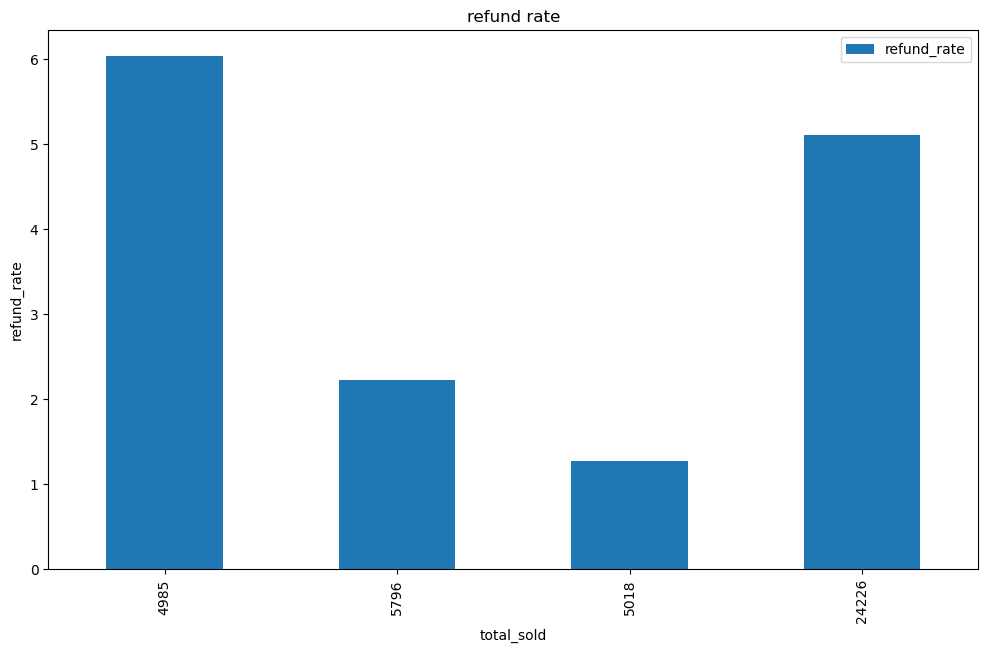

In [90]:
refund_analysis.plot(kind='bar', x='total_sold',y='refund_rate',figsize=(12,7))

plt.title('refund rate')
plt.xlabel('total_sold')
plt.ylabel('refund_rate')
plt.show()

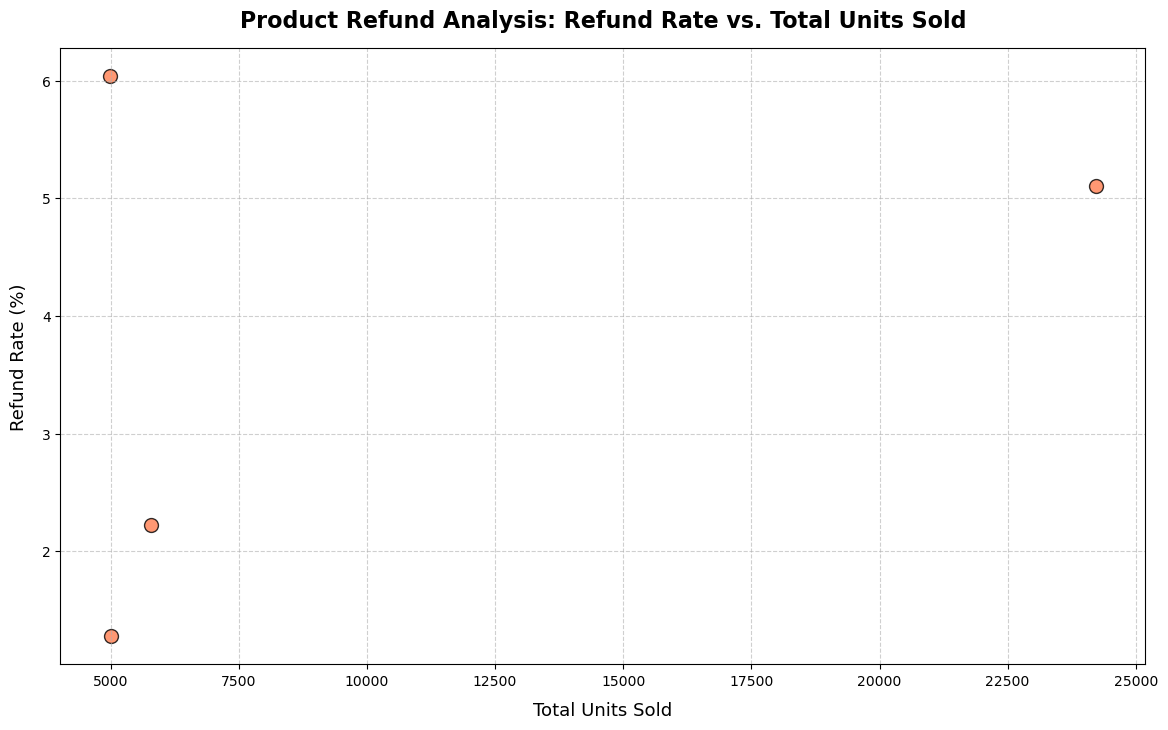

In [91]:
plt.figure(figsize=(14, 8))

# Scatter plot bananay ke liye
plt.scatter(
    refund_analysis['total_sold'], 
    refund_analysis['refund_rate'], 
    color='coral', 
    alpha=0.8, 
    edgecolors='black', 
    s=100  # Points ka size thora barha diya hai
)

# Titles aur Labels
plt.title('Product Refund Analysis: Refund Rate vs. Total Units Sold', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Total Units Sold', fontsize=13, labelpad=10)
plt.ylabel('Refund Rate (%)', fontsize=13, labelpad=10)

# Grid on karne ke liye
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

BUSINESS ANALYIS FROM VISULIZATIONS

VISULIZATION1

MONTHLY REVENUE AND GROSS PROFIT
revenue start main bht thora tha 2013 ka baad increase hona start hwa , 2014, main apnii peak pr tha lakin us k baad phir thora hogya, 







visulization2

### Product-Wise Financial Performance Summary

* **Top-Performing Product ("The Original Mr. Fuzzy"):**
* Generates the vast majority of total revenue (over $\$1.2\text{M}$) and gross profit ($\approx \$738\text{K}$), acting as the primary revenue driver for the business.


* **Consistent Cost Margins:**
* The ratio between COGS (Cost of Goods Sold) and Gross Profit remains steady and proportional across all four products, reflecting healthy product-level profit margins.


* **Secondary Portfolio Products:**
* Items such as *The Forever Love Bear*, *The Birthday Sugar Panda*, and *The Hudson River Mini bear* contribute a steady secondary stream of revenue and profit, though at a much smaller scale.



---

### Business Recommendations

* **Diversify Marketing and Focus:**
* Reduce reliance on a single core product by running targeted promotional campaigns or bundle deals for the secondary products to boost their sales volume.


* **Inventory and Supply Chain Optimization:**
* Prioritize inventory management and stock availability for *The Original Mr. Fuzzy* to prevent stockouts, given its heavy impact on overall business earnings.

VISULIZATION 3

total session by channel shows google,non brand was most dominant channel , nest come bsearch nonbrand, , total orders totally correspond to total sessions , business recomendtion can include , keep advertising on google and non brand but also keep a huge focous on non brand and other sociaal searches

VISULIZATION 4
### Channel Performance Analysis Summary

* **Dominant Traffic & Order Driver (`gsearch / nonbrand`):**
* The `gsearch / nonbrand` channel dominates completely, driving the vast majority of web traffic ($\approx 282,706$ sessions) and total orders ($\approx 18,822$). It serves as the core acquisition engine for the business.


* **Strong Brand Awareness (`gsearch / brand`):**
* `gsearch / brand` performs as the second strongest segment, pulling in healthy user intent with $33,329$ sessions and $2,511$ orders, indicating solid organic or branded recall on Google.


* **Secondary Channels (`bsearch` & `socialbook`):**
* Both `bsearch` (brand/nonbrand) and `socialbook` (desktop targeted/pilot) generate minor traffic volume and orders by comparison, showing niche or supplementary reach rather than core conversion power.



---

### Business Recommendations

* **Optimize Paid Search Allocation:**
* Keep heavy advertising and budget focus on `gsearch / nonbrand` to capture broad market demand, while continuously optimizing cost-per-acquisition (CPA) to protect margins.


* **Scale & Retarget via Brand Search:**
* Leverage `gsearch / brand` campaigns for retargeting high-intent visitors who are already familiar with the brand to maximize final conversion rates.


* **Re-evaluate Social & BSearch Channels:**
* Review the ROI on `socialbook` and `bsearch` campaigns; if conversion rates or customer acquisition costs are unfavorable compared to Google Search, reallocate budgets to higher-performing segments.


visulization 4
### Product Refund Analysis Summary

* **Volume vs. Refund Rate Trade-off:**
* High-volume products experience significant returns, while lower-selling items show varied refund percentages.

### Business Recommendations

* **Investigate High-Refund Items:**
* Inspect product quality and customer descriptions for items showing elevated refund rates to prevent customer dissatisfaction.


* **Balance Sales Focus:**
* Ensure scaling top-selling products does not compromise quality control or trigger higher return overheads.


In [92]:
df_maven



,Table,Field,Description
0,orders,order_id,Unique identifier for each order (PK)
1,orders,created_at,Timestamp when the order was placed
2,orders,website_session_id,Unique identifier for the website session (FK)
3,orders,user_id,Unique identifier for the user (FK)
4,orders,primary_product_id,Unique identifier for the primary product in t...
5,orders,items_purchased,Number of items in the order
6,orders,price_usd,Total price for the items in the order
7,orders,cogs_usd,Cost of goods sold for the items in the order
8,order_items,order_item_id,Unique identifier for each order item (PK)
9,order_items,created_at,Timestamp when the order was placed


In [93]:
print("ORDER ITEMS")
print("Shape:", df_order_item.shape)
print("Columns:", df_order_item.columns.tolist())
print("\nData types:")
print(df_order_item.dtypes)

print("\nREFUNDS")
print("Shape:", refunds_check.shape)
print("Columns:", refunds_check.columns.tolist())
print("\nData types:")
print(refunds_check.dtypes)

ORDER ITEMS
Shape: (40025, 7)
Columns: ['order_item_id', 'created_at', 'order_id', 'product_id', 'is_primary_item', 'price_usd', 'cogs_usd']

Data types:
order_item_id        int64
created_at          object
order_id             int64
product_id           int64
is_primary_item      int64
price_usd          float64
cogs_usd           float64
dtype: object

REFUNDS
Shape: (1731, 5)
Columns: ['order_item_refund_id', 'created_at', 'order_item_id', 'order_id', 'refund_amount_usd']

Data types:
order_item_refund_id             int64
created_at              datetime64[ns]
order_item_id                    int64
order_id                         int64
refund_amount_usd              float64
dtype: object


In [94]:
# Check item-level uniqueness
print("Total item records:", len(df_order_item))
print("Unique item IDs:", df_order_item["order_item_id"].nunique())

# Check refund item IDs
print("\nTotal refund records:", len(refunds_check))
print("Unique refunded item IDs:",
      refunds_check["order_item_id"].nunique())

# Convert purchase date to datetime
df_order_item["created_at"] = pd.to_datetime(
    df_order_item["created_at"],
    errors="coerce"
)

print("\nPurchase date range:")
print(df_order_item["created_at"].min())
print(df_order_item["created_at"].max())

print("\nInvalid purchase dates:",
      df_order_item["created_at"].isna().sum())

Total item records: 40025
Unique item IDs: 40025

Total refund records: 1731
Unique refunded item IDs: 1731

Purchase date range:
2012-03-19 10:42:46
2015-03-19 05:38:31

Invalid purchase dates: 0


In [95]:
# Find refund item IDs that do not exist in order items
unmatched_refunds = refunds_check.loc[
    ~refunds_check["order_item_id"].isin(
        df_order_item["order_item_id"]
    )
]

print("Unmatched refund records:", len(unmatched_refunds))

Unmatched refund records: 0


In [96]:
# Match each refund to its purchased item
refund_timing = refunds_check.merge(
    df_order_item[
        ["order_item_id", "created_at"]
    ],
    on="order_item_id",
    how="left",
    suffixes=("_refund", "_purchase"),
    validate="one_to_one"
)

# Calculate elapsed time between purchase and refund
refund_timing["days_to_refund"] = (
    refund_timing["created_at_refund"]
    - refund_timing["created_at_purchase"]
).dt.total_seconds() / (24 * 60 * 60)

# Inspect the results
print(refund_timing[
    ["order_item_id", "created_at_purchase",
     "created_at_refund", "days_to_refund"]
].head())

print("\nSummary of days to refund:")
print(refund_timing["days_to_refund"].describe())

   order_item_id created_at_purchase   created_at_refund  days_to_refund
0             57 2012-03-31 02:32:43 2012-04-06 11:32:43        6.375000
1             74 2012-04-03 19:09:43 2012-04-13 01:09:43        9.250000
2             71 2012-04-03 15:03:48 2012-04-15 07:03:48       11.666667
3            118 2012-04-15 09:00:37 2012-04-17 20:00:37        2.458333
4            116 2012-04-13 14:53:49 2012-04-22 20:53:49        9.250000

Summary of days to refund:
count    1731.000000
mean        9.030714
std         4.039151
min         2.000000
25%         5.416667
50%         9.250000
75%        12.437500
max        16.000000
Name: days_to_refund, dtype: float64


In [97]:
print("Latest item purchase:")
print(df_order_item["created_at"].max())

print("\nLatest recorded refund:")
print(refunds_check["created_at"].max())

print("\nEarliest recorded refund:")
print(refunds_check["created_at"].min())

# Candidate cutoff for a 30-day prediction window
data_end = df_order_item["created_at"].max()
cutoff_date = data_end - pd.Timedelta(days=30)

print("\nCandidate 30-day cutoff:")
print(cutoff_date)

print("\nItems purchased after the cutoff:")
print(
    (df_order_item["created_at"] > cutoff_date).sum()
)

Latest item purchase:
2015-03-19 05:38:31

Latest recorded refund:
2015-04-01 18:11:08

Earliest recorded refund:
2012-04-06 11:32:43

Candidate 30-day cutoff:
2015-02-17 05:38:31

Items purchased after the cutoff:
2776


In [98]:
# Provisional eligibility cutoff
cutoff_date = (
    df_order_item["created_at"].max()
    - pd.Timedelta(days=30)
)

# Items purchased within the proposed eligibility period
eligible_items = df_order_item.loc[
    df_order_item["created_at"] <= cutoff_date
]

# Refund records associated with purchases after the cutoff
late_purchase_refunds = refund_timing.loc[
    refund_timing["created_at_purchase"] > cutoff_date
]

print("Provisional cutoff:", cutoff_date)
print("Eligible item records:", len(eligible_items))
print("Refunded items from late purchases:",
      len(late_purchase_refunds))

print("\nPurchase dates of those refunded items:")
print(
    late_purchase_refunds["created_at_purchase"]
    .describe()
)

Provisional cutoff: 2015-02-17 05:38:31
Eligible item records: 37249
Refunded items from late purchases: 93

Purchase dates of those refunded items:
count                               93
mean     2015-03-04 05:15:42.763440896
min                2015-02-17 09:46:53
25%                2015-02-25 15:38:48
50%                2015-03-04 09:55:14
75%                2015-03-10 20:47:15
max                2015-03-18 10:37:23
Name: created_at_purchase, dtype: object


In [99]:
# Provisional assumption: refund outcomes are observed through
# the latest recorded refund timestamp
observation_end = refunds_check["created_at"].max()

# Latest purchase timestamp that allows 30 full days
# before the provisional observation endpoint
cutoff_30d = observation_end - pd.Timedelta(days=30)

eligible_30d = df_order_item.loc[
    df_order_item["created_at"] <= cutoff_30d
]

print("Provisional observation endpoint:", observation_end)
print("Provisional 30-day purchase cutoff:", cutoff_30d)
print("Eligible items:", len(eligible_30d))
print("Items excluded:", len(df_order_item) - len(eligible_30d))

Provisional observation endpoint: 2015-04-01 18:11:08
Provisional 30-day purchase cutoff: 2015-03-02 18:11:08
Eligible items: 38455
Items excluded: 1570


In [100]:
# Identify refund records occurring more than 30 days
# after the corresponding purchase
refunds_over_30d = refund_timing.loc[
    refund_timing["days_to_refund"] > 30
]

print("Refund records:", len(refund_timing))
print("Refunds after 30 days:", len(refunds_over_30d))

print("\nMaximum days to refund:",
      refund_timing["days_to_refund"].max())

Refund records: 1731
Refunds after 30 days: 0

Maximum days to refund: 16.0


In [101]:
# Define the provisional observation boundary
observation_end = df_order_item["created_at"].max()

# Keep only items with a full 30-day observation window
cutoff_30d = observation_end - pd.Timedelta(days=30)

model_items = df_order_item.loc[
    df_order_item["created_at"] <= cutoff_30d
].copy()

# Identify items refunded within 30 days
refunded_item_ids = set(
    refund_timing.loc[
        refund_timing["days_to_refund"] <= 30,
        "order_item_id"
    ]
)

# Create the target variable
model_items["refunded_30d"] = (
    model_items["order_item_id"]
    .isin(refunded_item_ids)
    .astype(int)
)

# Validate the target
print("Modeling rows:", len(model_items))
print("\nTarget counts:")
print(model_items["refunded_30d"].value_counts())

print("\nTarget proportions:")
print(model_items["refunded_30d"].value_counts(normalize=True))

Modeling rows: 37249

Target counts:
refunded_30d
0    35611
1     1638
Name: count, dtype: int64

Target proportions:
refunded_30d
0    0.956026
1    0.043974
Name: proportion, dtype: float64


In [102]:
model_items.head()

,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd,refunded_30d
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49,0
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49,0
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49,0
3,4,2012-03-20 09:41:45,4,1,1,49.99,19.49,0
4,5,2012-03-20 11:28:15,5,1,1,49.99,19.49,0


test/target split

In [119]:
# 1. Check dataset size and item-level uniqueness
print("Total rows:", len(model_items))
print("Unique item IDs:", model_items["order_item_id"].nunique())

# 2. Inspect the target distribution
print("\nRefund target counts:")
print(model_items["refunded_30d"].value_counts().sort_index())

print("\nRefund target percentages:")
print(
    (model_items["refunded_30d"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# 3. Check for missing target labels
print("\nMissing target values:",
      model_items["refunded_30d"].isna().sum())

Total rows: 37249
Unique item IDs: 37249

Refund target counts:
refunded_30d
0    35611
1     1638
Name: count, dtype: int64

Refund target percentages:
refunded_30d
0    95.6
1     4.4
Name: proportion, dtype: float64

Missing target values: 0


In [120]:
# Inspect the candidate modeling features
print("Modeling dataset columns:")
print(model_items.columns.tolist())

print("\nMissing values:")
print(model_items.isna().sum())

print("\nUnique values in candidate categorical/integer columns:")
for col in ["product_id", "is_primary_item"]:
    print(f"\n{col}:")
    print(model_items[col].value_counts(dropna=False).sort_index())

Modeling dataset columns:
['order_item_id', 'created_at', 'order_id', 'product_id', 'is_primary_item', 'price_usd', 'cogs_usd', 'refunded_30d', 'purchase_year', 'purchase_month', 'purchase_dayofweek']

Missing values:
order_item_id         0
created_at            0
order_id              0
product_id            0
is_primary_item       0
price_usd             0
cogs_usd              0
refunded_30d          0
purchase_year         0
purchase_month        0
purchase_dayofweek    0
dtype: int64

Unique values in candidate categorical/integer columns:

product_id:
product_id
1    22806
2     5437
3     4558
4     4448
Name: count, dtype: int64

is_primary_item:
is_primary_item
0     6998
1    30251
Name: count, dtype: int64


In [121]:
product_refund_analysis = (
    model_items.groupby("product_id")
    .agg(
        total_items=("order_item_id", "count"),
        refunded_items=("refunded_30d", "sum"),
        refund_rate=("refunded_30d", "mean")
    )
    .reset_index()
)

product_refund_analysis["refund_rate_pct"] = (
    product_refund_analysis["refund_rate"] * 100
).round(2)

print(
    product_refund_analysis[
        ["product_id", "total_items",
         "refunded_items", "refund_rate_pct"]
    ].sort_values("refund_rate_pct", ascending=False)
)

   product_id  total_items  refunded_items  refund_rate_pct
2           3         4558             272             5.97
0           1        22806            1191             5.22
1           2         5437             120             2.21
3           4         4448              55             1.24


In [122]:
price_analysis = (
    model_items.groupby("refunded_30d")["price_usd"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print(price_analysis)

              count   mean  median    min    max
refunded_30d                                    
0             35611  48.53   49.99  29.99  59.99
1              1638  49.39   49.99  29.99  59.99


In [123]:
primary_item_analysis = (
    model_items.groupby("is_primary_item")
    .agg(
        total_items=("order_item_id", "count"),
        refunded_items=("refunded_30d", "sum"),
        refund_rate=("refunded_30d", "mean")
    )
    .reset_index()
)

primary_item_analysis["refund_rate_pct"] = (
    primary_item_analysis["refund_rate"] * 100
).round(2)

print(
    primary_item_analysis[
        ["is_primary_item", "total_items",
         "refunded_items", "refund_rate_pct"]
    ]
)

   is_primary_item  total_items  refunded_items  refund_rate_pct
0                0         6998             174             2.49
1                1        30251            1464             4.84


In [124]:
product_price_check = (
    model_items.groupby("product_id")
    .agg(
        item_count=("order_item_id", "count"),
        unique_prices=("price_usd", "nunique"),
        average_price=("price_usd", "mean")
    )
    .round(2)
)

print(product_price_check)

            item_count  unique_prices  average_price
product_id                                          
1                22806              1          49.99
2                 5437              1          59.99
3                 4558              1          45.99
4                 4448              1          29.99


In [125]:

product_cost_check = (
    model_items.groupby("product_id")
    .agg(
        item_count=("order_item_id", "count"),
        unique_cogs=("cogs_usd", "nunique"),
        average_cogs=("cogs_usd", "mean")
    )
    .round(2)
)

print(product_cost_check)


            item_count  unique_cogs  average_cogs
product_id                                       
1                22806            1         19.49
2                 5437            1         22.49
3                 4558            1         14.49
4                 4448            1          9.49


In [126]:

print("Purchase date range:")
print("Earliest:", model_items["created_at"].min())
print("Latest:", model_items["created_at"].max())

print("\nItems by year:")
print(model_items["created_at"].dt.year.value_counts().sort_index())

print("\nItems by month:")
print(model_items["created_at"].dt.month.value_counts().sort_index())

print("\nItems by day of week (0 = Monday, 6 = Sunday):")
print(
    model_items["created_at"]
    .dt.dayofweek
    .value_counts()
    .sort_index()
)


Purchase date range:
Earliest: 2012-03-19 10:42:46
Latest: 2015-02-17 04:41:55

Items by year:
created_at
2012     2586
2013     7613
2014    22581
2015     4469
Name: count, dtype: int64

Items by month:
created_at
1     4347
2     3469
3     1872
4     2309
5     2552
6     2408
7     2518
8     2628
9     2873
10    3311
11    4218
12    4744
Name: count, dtype: int64

Items by day of week (0 = Monday, 6 = Sunday):
created_at
0    6538
1    6057
2    6234
3    6302
4    6467
5    2676
6    2975
Name: count, dtype: int64


In [127]:

model_items["purchase_year"] = model_items["created_at"].dt.year
model_items["purchase_month"] = model_items["created_at"].dt.month
model_items["purchase_dayofweek"] = model_items["created_at"].dt.dayofweek

print(
    model_items[
        ["created_at", "purchase_year", "purchase_month", "purchase_dayofweek"]
    ].head()
)


           created_at  purchase_year  purchase_month  purchase_dayofweek
0 2012-03-19 10:42:46           2012               3                   0
1 2012-03-19 19:27:37           2012               3                   0
2 2012-03-20 06:44:45           2012               3                   1
3 2012-03-20 09:41:45           2012               3                   1
4 2012-03-20 11:28:15           2012               3                   1


In [128]:

monthly_refunds = (
    model_items.groupby("purchase_month")
    .agg(
        total_items=("order_item_id", "count"),
        refunded_items=("refunded_30d", "sum"),
        refund_rate=("refunded_30d", "mean")
    )
)

monthly_refunds["refund_rate"] = (
    monthly_refunds["refund_rate"] * 100
).round(2)

print(monthly_refunds)


                total_items  refunded_items  refund_rate
purchase_month                                          
1                      4347             165         3.80
2                      3469             111         3.20
3                      1872              67         3.58
4                      2309              83         3.59
5                      2552              90         3.53
6                      2408             134         5.56
7                      2518             120         4.77
8                      2628             204         7.76
9                      2873             223         7.76
10                     3311             105         3.17
11                     4218             162         3.84
12                     4744             174         3.67


In [129]:

monthly_yearly_refunds = (
    model_items.groupby(["purchase_year", "purchase_month"])
    .agg(
        total_items=("order_item_id", "count"),
        refunded_items=("refunded_30d", "sum"),
        refund_rate=("refunded_30d", "mean")
    )
)

monthly_yearly_refunds["refund_rate"] = (
    monthly_yearly_refunds["refund_rate"] * 100
).round(2)

print(monthly_yearly_refunds.to_string())


                              total_items  refunded_items  refund_rate
purchase_year purchase_month                                          
2012          3                        60               1         1.67
              4                        99               5         5.05
              5                       108               4         3.70
              6                       140               8         5.71
              7                       169              14         8.28
              8                       228              17         7.46
              9                       287              26         9.06
              10                      371              27         7.28
              11                      618              46         7.44
              12                      506              30         5.93
2013          1                       390              18         4.62
              2                       498              26         5.22
      

In [130]:

aug_sep_2014 = model_items.loc[
    (model_items["purchase_year"] == 2014)
    & (model_items["purchase_month"].isin([8, 9]))
]

product_month_refunds = (
    aug_sep_2014.groupby(["purchase_month", "product_id"])
    .agg(
        total_items=("order_item_id", "count"),
        refunded_items=("refunded_30d", "sum"),
        refund_rate=("refunded_30d", "mean")
    )
)

product_month_refunds["refund_rate"] = (
    product_month_refunds["refund_rate"] * 100
).round(2)

print(product_month_refunds.to_string())


                           total_items  refunded_items  refund_rate
purchase_month product_id                                          
8              1                   958             132        13.78
               2                   237               4         1.69
               3                   294              20         6.80
               4                   303               2         0.66
9              1                  1056             140        13.26
               2                   251               8         3.19
               3                   317              21         6.62
               4                   327               4         1.22


In [131]:

weekday_refunds = (
    model_items.groupby("purchase_dayofweek")
    .agg(
        total_items=("order_item_id", "count"),
        refunded_items=("refunded_30d", "sum"),
        refund_rate=("refunded_30d", "mean")
    )
)

weekday_refunds["refund_rate"] = (
    weekday_refunds["refund_rate"] * 100
).round(2)

weekday_refunds.index = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

print(weekday_refunds)


           total_items  refunded_items  refund_rate
Monday            6538             304         4.65
Tuesday           6057             240         3.96
Wednesday         6234             266         4.27
Thursday          6302             282         4.47
Friday            6467             283         4.38
Saturday          2676             114         4.26
Sunday            2975             149         5.01


In [132]:

model_items = model_items.sort_values("created_at").copy()

split_position = int(len(model_items) * 0.80)
split_date = model_items.iloc[split_position]["created_at"]

print("Total items:", len(model_items))
print("Proposed split date:", split_date)
print(
    "Training period:",
    model_items["created_at"].min(),
    "to",
    model_items.iloc[split_position - 1]["created_at"]
)
print(
    "Testing period:",
    split_date,
    "to",
    model_items["created_at"].max()
)


Total items: 37249
Proposed split date: 2014-12-01 09:23:13
Training period: 2012-03-19 10:42:46 to 2014-12-01 09:22:13
Testing period: 2014-12-01 09:23:13 to 2015-02-17 04:41:55


In [133]:

train_items = model_items.loc[
    model_items["created_at"] < split_date
].copy()

test_items = model_items.loc[
    model_items["created_at"] >= split_date
].copy()

print("Training rows:", len(train_items))
print("Testing rows:", len(test_items))

print("\nTraining target distribution:")
print(train_items["refunded_30d"].value_counts())
print((train_items["refunded_30d"].value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print(test_items["refunded_30d"].value_counts())
print((test_items["refunded_30d"].value_counts(normalize=True) * 100).round(2))


Training rows: 29799
Testing rows: 7450

Training target distribution:
refunded_30d
0    28405
1     1394
Name: count, dtype: int64
refunded_30d
0    95.32
1     4.68
Name: proportion, dtype: float64

Testing target distribution:
refunded_30d
0    7206
1     244
Name: count, dtype: int64
refunded_30d
0    96.72
1     3.28
Name: proportion, dtype: float64


In [134]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_test = test_items["refunded_30d"]
baseline_predictions = [0] * len(y_test)

print("Accuracy:", round(accuracy_score(y_test, baseline_predictions), 4))
print("Precision:", precision_score(y_test, baseline_predictions, zero_division=0))
print("Recall:", recall_score(y_test, baseline_predictions, zero_division=0))
print("F1:", f1_score(y_test, baseline_predictions, zero_division=0))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, baseline_predictions))


Accuracy: 0.9672
Precision: 0.0
Recall: 0.0
F1: 0.0

Confusion matrix:
[[7206    0]
 [ 244    0]]


In [135]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

features = [
    "product_id",
    "is_primary_item",
    "purchase_month",
    "purchase_dayofweek"
]

X_train = train_items[features]
y_train = train_items["refunded_30d"]

X_test = test_items[features]
y_test = test_items["refunded_30d"]

model = DecisionTreeClassifier(
    max_depth=4,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print("Confusion matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))

print("PR-AUC (average precision):",
      round(average_precision_score(y_test, probabilities), 4))


Confusion matrix:
[[7065  141]
 [ 235    9]]

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.97      7206
           1       0.06      0.04      0.05       244

    accuracy                           0.95      7450
   macro avg       0.51      0.51      0.51      7450
weighted avg       0.94      0.95      0.94      7450

PR-AUC (average precision): 0.0431


In [136]:

import pandas as pd

probability_summary = pd.DataFrame({
    "actual_refund": y_test.to_numpy(),
    "refund_probability": probabilities
})

print("Predicted probability distribution:")
print(
    probability_summary["refund_probability"]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .round(4)
)

print("\nMean predicted probability by actual outcome:")
print(
    probability_summary.groupby("actual_refund")["refund_probability"]
    .agg(["count", "mean", "median", "max"])
    .round(4)
)


Predicted probability distribution:
count    7450.0000
mean        0.3890
std         0.1440
min         0.0000
50%         0.4615
75%         0.4615
90%         0.4615
95%         0.4787
99%         0.6090
max         0.6090
Name: refund_probability, dtype: float64

Mean predicted probability by actual outcome:
               count    mean  median    max
actual_refund                              
0               7206  0.3874  0.4615  0.609
1                244  0.4364  0.4615  0.609


In [137]:

from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
    threshold_predictions = (probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "flagged_items": int(threshold_predictions.sum()),
        "precision": precision_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "f1": f1_score(
            y_test, threshold_predictions, zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

print(threshold_results.round(3).to_string(index=False))


 threshold  flagged_items  precision  recall    f1
      0.30           5584      0.039   0.902 0.075
      0.35           5584      0.039   0.902 0.075
      0.40           5584      0.039   0.902 0.075
      0.45           5584      0.039   0.902 0.075
      0.50            150      0.060   0.037 0.046


In [138]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, classification_report

categorical_features = ["product_id"]
numeric_features = [
    "is_primary_item",
    "purchase_month",
    "purchase_dayofweek"
]

preprocessor = ColumnTransformer([
    ("product", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numeric", StandardScaler(), numeric_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Classification report:")
print(classification_report(
    y_test, logistic_predictions, zero_division=0
))

print("PR-AUC (average precision):",
      round(average_precision_score(y_test, logistic_probabilities), 4))


Classification report:
              precision    recall  f1-score   support

           0       0.98      0.39      0.56      7206
           1       0.04      0.82      0.08       244

    accuracy                           0.40      7450
   macro avg       0.51      0.61      0.32      7450
weighted avg       0.95      0.40      0.54      7450

PR-AUC (average precision): 0.0515


# ** 4. Machine Learning: Refund Prediction

4.1 Prediction objective

The modeling question was:

Can we use information available at the time of purchase to predict whether an item will be refunded within 30 days?

The unit of analysis was one purchased item, identified by order_item_id.

The target variable was refunded_30d:

1: The item had a linked refund record within 30 days.

0: No qualifying refund was recorded within 30 days.

The modeling dataset was restricted to purchases made on or before February 17, 2015, using the latest purchase timestamp minus 30 days as a provisional cutoff.

This produced 37,249 eligible items, of which 1,638 were refunded within 30 days.

Target class

Items

Share

Not refunded

35,611

95.6%

Refunded

1,638

4.4%

Total

37,249

100%

The target was highly imbalanced: fewer than 5% of eligible items were refunded.

Important limitation: The cutoff is provisional because the completeness and observation window of the original refund records have not been independently confirmed.

## **4.2 Feature selection

The initial predictors were:

product_id

is_primary_item

purchase_month

purchase_dayofweek

Purchase year was investigated during exploratory analysis, but it was not included in the initial models. Year and time-related patterns may reflect changes in the business or data collection rather than stable relationships.

The following fields were excluded from the initial predictors:

order_item_id and raw order_id, because they are identifiers rather than meaningful behavioral features.

Refund dates and refund amounts, because they are only available after the refund and would leak information about the target.

price_usd and cogs_usd, because each product had a constant price and cost in this dataset, making these fields redundant with product identity for the initial experiment.

Feature selection must always reflect what would genuinely be available at the moment a prediction is made.

## **4.3 Train-test split

The dataset was sorted by purchase timestamp and divided chronologically:

Dataset

Items

Refunded items

Refund prevalence

Training

29,799

1,394

4.68%

Testing

7,450

244

3.28%

A chronological split was used instead of a random split to approximate the challenge of predicting refunds for later purchases using historical data.

The difference between the training and test refund rates suggests that the target distribution changed over time. This is a potential form of distribution drift and makes reliable future prediction more difficult.

## **4.4 Baseline model

A simple baseline predicted that no item would be refunded.

Its test accuracy was 96.72%, but it detected zero refunds.

This demonstrates why accuracy alone is misleading for imbalanced classification. A model can achieve apparently high accuracy while failing to identify the business outcome we actually care about.

## **4.5 Models evaluated

Two initial classifiers were tested: a class-weighted Decision Tree and a class-weighted Logistic Regression model.

Test metric

Decision Tree

Logistic Regression

Accuracy

Approximately 95%

Approximately 40%

Refund precision

0.06

0.04

Refund recall

0.04

0.82

Refund F1-score

0.05

0.08

Average precision (PR-AUC summary)

0.0431

0.0515

The average precision values were compared with a test-set refund prevalence of 0.0328. Both models performed above that reference level, but their results were weak.

The models also behaved differently:

Decision Tree: At its default threshold, the model identified only 9 of the 244 refunded items. Lowering the threshold increased recall, but at the examined lower thresholds it flagged approximately 5,584 of the 7,450 test items. Only around 3.9% of those flagged items were actually refunded.

Logistic Regression: The model identified approximately 82% of refunded items at its default threshold, but precision was only around 4%. This means most items flagged as likely refunds were not refunded. Its low accuracy also reflects the large number of non-refunded items classified as positive.

Neither model currently provides a sufficiently reliable basis for automatically intervening with customers or making operational decisions.

## **5. Interpretation and Business Value

The main value of this experiment is not that it produced a ready-to-deploy prediction system. It established a baseline, exposed the difficulty of predicting a rare outcome, and identified limitations that need to be addressed before a production-quality model could be justified.

The findings suggest several useful business questions:

Why did refund rates vary so substantially across products?

What explains the elevated rates in August and September 2014?

Did product mix, business changes, or data-collection changes contribute to the shift in refund prevalence over time?

What additional information available at purchase could improve predictions?

What level of precision and recall would be economically useful, given the cost of investigating false alarms and the cost of missing genuine refunds?

The analysis does not establish the causes of refunds. The observed patterns should guide investigation rather than be treated as causal conclusions.

## **6. Limitations

The following limitations should accompany any presentation of the project:

Rare outcome: Refunds account for a small proportion of purchased items.

Limited features: The initial models use only product identity, primary-item status, and basic calendar features.

Unconfirmed observation window: The refund-data completeness and provisional 30-day cutoff need verification against the source documentation.

Time-related variation: Refund prevalence differs between the training and test periods.

Threshold exploration: The test set was used to inspect alternative thresholds and compare model behavior. Consequently, the reported test results are exploratory rather than an unbiased final evaluation.

Limited causal interpretation: Product and time associations do not explain the reasons behind refunds.

No deployment validation: The models have not been validated in a live business workflow.

A stronger future evaluation would use a separate validation period for model and threshold selection, followed by an untouched final test period. Additional features should only be added when they are reliable and available at prediction time.

## **7. Final Conclusion

This project combined relational data analysis with an initial machine learning experiment on an e-commerce dataset.

The analytics phase quantified financial performance, identified product-level refund differences, explored website traffic, and highlighted periods with elevated refund rates. The modeling phase translated the business question into an item-level classification problem, addressed class imbalance, applied a chronological train-test split, and compared a baseline with two classifiers.

The current models are not ready for deployment, but the experiment demonstrates an important analytical principle: a high accuracy score does not necessarily mean a model is useful, especially when the outcome is rare.

The next priority is to communicate the work clearly, document its limitations, and publish a reproducible project repository. That will make the work easier for recruiters, clients, and other analysts to evaluate.